## Results

In [50]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sys, json, math, subprocess, tempfile
from pathlib import Path
from IPython.display import display
from lander.params import P
from lander.lcvx import LanderSOCP, solve_min_fuel, solve_min_landing_error, is_lossless
from lander.pointmass import simulate, glide_violation, run_b1, B1_CASES
import time
from lander.nonconvex import nonconvex_baseline

### Question 3.1

In [21]:
x0 = np.array([-6.0, 10.0, -2.0, -1.0])   # x, y, vx, vy
prob = LanderSOCP(P)
sol, evals = solve_min_fuel(prob, x0)

print("t_f =", sol.tgo)
print("carburant (g) =", 1000 * sol.fuel)
print("certifié :", is_lossless(sol))

t_f = 2.905433182352464
carburant (g) = 155.55229881109867
certifié : True


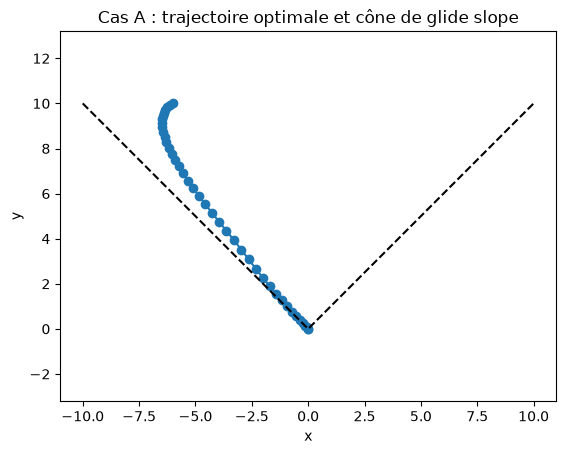

In [ ]:
plt.plot(sol.p[:, 0], sol.p[:, 1], "o-")
plt.plot([-10, 0, 10], [10, 0, 10], "k--")   # 45deg cone
plt.xlabel("x"); plt.ylabel("y"); plt.axis("equal")
plt.title("Cas A : trajectoire optimale et cône de glide slope")
plt.show()

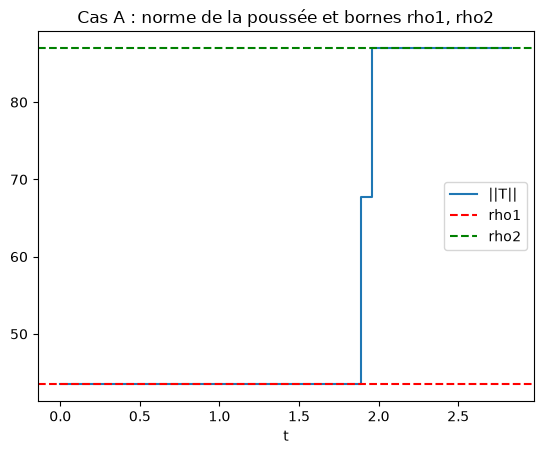

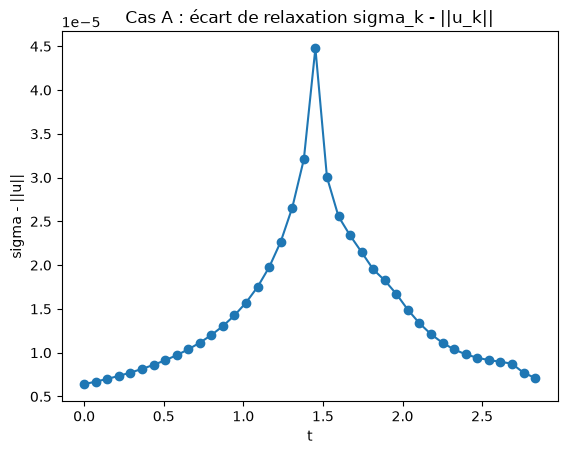

In [23]:
T = np.linalg.norm(sol.thrust, axis=1)
plt.step(sol.t[:-1], T, where="post", label="||T||")
plt.axhline(P.rho1, color="r", ls="--", label="rho1")
plt.axhline(P.rho2, color="g", ls="--", label="rho2")
plt.legend(); plt.xlabel("t")
plt.title("Cas A : norme de la poussée et bornes rho1, rho2")
plt.show()

plt.plot(sol.t[:-1], sol.relaxation_gap, "o-")
plt.xlabel("t"); plt.ylabel("sigma - ||u||")
plt.title("Cas A : écart de relaxation sigma_k - ||u_k||")
plt.show()

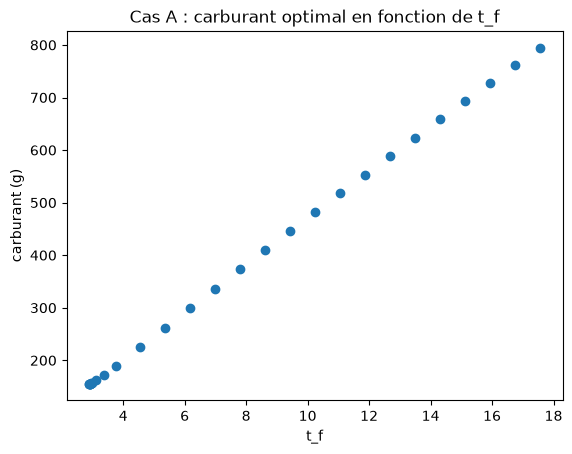

In [24]:
tf = [e[0] for e in evals if np.isfinite(e[1])]
fuel = [1000 * e[1] for e in evals if np.isfinite(e[1])]
plt.plot(tf, fuel, "o")
plt.xlabel("t_f"); plt.ylabel("carburant (g)")
plt.title("Cas A : carburant optimal en fonction de t_f")
plt.show()

In [25]:
for mode in ["accel", "thrust"]:
    sim = simulate(sol, mode=mode)
    print(f"{mode:6s} | erreur position = {100*sim['final_pos_err']:.3f} cm"
          f" | erreur vitesse = {100*sim['final_vel_err']:.3f} cm/s"
          f" | carburant = {1000*sim['fuel']:.1f} g")

accel  | erreur position = 0.000 cm | erreur vitesse = 0.000 cm/s | carburant = 155.6 g
thrust | erreur position = 1.212 cm | erreur vitesse = 1.295 cm/s | carburant = 155.6 g


In [26]:
tf = sol.tgo   # t_f optimal du SOCP (N=40)

# SLSQP sur le problème original (P), 12 initialisations aléatoires
runs = nonconvex_baseline(x0, tf, N=20, n_starts=12)

# SOCP avec le même N et le même t_f
prob20 = LanderSOCP(P, N=20)
prob20.solve(x0, tf)                       # 1er solve : compilation CVXPY
t0 = time.perf_counter()
sol20 = prob20.solve(x0, tf)               # 2e solve : temps réel du solveur
t_socp = time.perf_counter() - t0

# détail des 12 essais SLSQP
print("essai | converge | faisable | carburant (g) | temps (s)")
for i, r in enumerate(runs):
    print(f"{i:5d} | {str(r['converged']):8s} | {str(r['feasible']):8s} | "
          f"{1000*r['fuel']:13.1f} | {r['time']:.3f}")

# tableau récapitulatif
ok = [r for r in runs if r["feasible"]]
fuels = [1000*r["fuel"] for r in ok]
print("\nMéthode | carburant (g) | fiabilité | temps (s)")
print(f"SLSQP   | {min(fuels):.1f} à {max(fuels):.1f}" if ok else "SLSQP   | aucun faisable",
      f"| {len(ok)}/12 faisables | {np.mean([r['time'] for r in runs]):.3f} (moyenne)")
if sol20 is not None:
    print(f"SOCP    | {1000*sol20.fuel:.1f} | 1/1, certifié = {is_lossless(sol20)} | {t_socp:.4f}")
else:
    print("SOCP    | infaisable à N=20 pour ce t_f")

essai | converge | faisable | carburant (g) | temps (s)
    0 | True     | True     |         155.8 | 17.210
    1 | True     | True     |         156.3 | 22.186
    2 | True     | True     |         156.5 | 45.243
    3 | False    | True     |         156.4 | 57.086
    4 | True     | True     |         156.9 | 22.701
    5 | True     | True     |         156.8 | 39.960
    6 | True     | True     |         157.5 | 19.121
    7 | False    | True     |         156.7 | 57.293
    8 | True     | True     |         156.6 | 25.043
    9 | False    | True     |         156.3 | 55.787
   10 | True     | True     |         157.0 | 51.384
   11 | True     | True     |         156.9 | 41.454

Méthode | carburant (g) | fiabilité | temps (s)
SLSQP   | 155.8 à 157.5 | 12/12 faisables | 37.872 (moyenne)
SOCP    | 155.7 | 1/1, certifié = True | 0.0147


### Question 3.2

Pad center reachable in relaxed search: False
Stage 1 minimum miss distance: 2.496113229 m
Flight time: 3.649066977 s
Stage 2 miss distance: 2.497113234 m
Fuel used: 169.993406 g
Fuel remaining: 0.006594 g
Lossless: True
Maximum relative gap: 5.52953647e-08
Simulated position error from planned touchdown: 7.75251596e-13 m
Simulated terminal speed: 1.19898536e-13 m/s
Thrust violation: 0.0338622426 N
Glide-slope violation: 0.00224624531 m


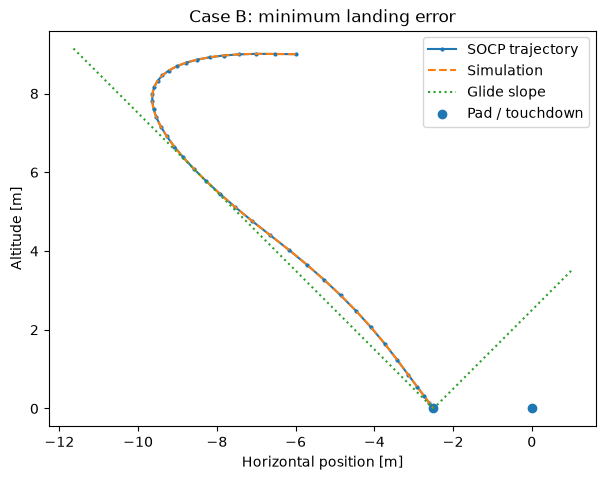

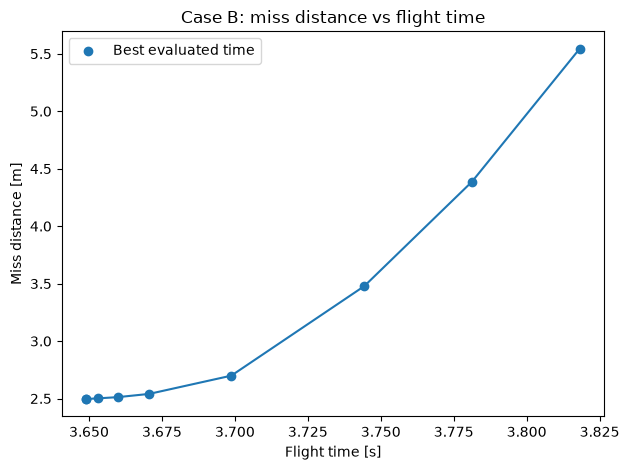

In [29]:
x0 = np.array([-6., 9., -6., 0.])
m0 = P.m_dry + 0.17
center = LanderSOCP(P, N=40)
# Rejecting uncertified solutions alone does not establish infeasibility.
relaxed, _ = solve_min_fuel(center, x0, m0, certify=False)
print('Pad center reachable in relaxed search:', relaxed is not None)
assert relaxed is None, 'A relaxed center solution was found; investigate.'
sol, d_star, evaluations = solve_min_landing_error(P, x0, m0, N=40)
if sol is None:
    raise RuntimeError(f'No certified two-stage solution; Stage 1 d* = {d_star}')
sim = simulate(sol, P, mode='accel')
report = '\n'.join([
    f'Stage 1 minimum miss distance: {d_star:.9f} m',
    f'Flight time: {sol.tgo:.9f} s',
    f'Stage 2 miss distance: {sol.landing_error:.9f} m',
    f'Fuel used: {1000*sol.fuel:.6f} g',
    f'Fuel remaining: {1000*(0.17-sol.fuel):.6f} g',
    f'Lossless: {is_lossless(sol)}',
    f'Maximum relative gap: {np.max(sol.relaxation_gap/np.maximum(sol.sigma,1e-9)):.9g}',
    f'Simulated position error from planned touchdown: {sim["final_pos_err"]:.9g} m',
    f'Simulated terminal speed: {sim["final_vel_err"]:.9g} m/s',
    f'Thrust violation: {sim["thrust_violation"]:.9g} N',
    f'Glide-slope violation: {glide_violation(sim["traj"], 1.):.9g} m',
])
print(report)

# Trajectoire
fig, ax = plt.subplots()
ax.plot(sol.p[:,0], sol.p[:,1], 'o-', markersize=2, label='SOCP trajectory')
ax.plot(sim['traj'][:,0], sim['traj'][:,1], '--', label='Simulation')
xx = np.linspace(min(sol.p[:,0].min(), sol.p[-1,0]) - 2, max(0., sol.p[:,0].max()) + 1, 300)
ax.plot(xx, abs(xx - sol.p[-1,0]), ':', label='Glide slope')
ax.scatter([0, sol.p[-1,0]], [0, 0], label='Pad / touchdown')
ax.set(xlabel='Horizontal position [m]', ylabel='Altitude [m]', title='Case B: minimum landing error')
ax.set_aspect('equal'); ax.legend(); fig.tight_layout()
plt.show()

# Erreur d'atterrissage en fonction de t_f
fig, ax = plt.subplots()
vals = np.asarray(evaluations); mask = np.isfinite(vals[:,1])
ax.plot(vals[mask,0], vals[mask,1], 'o-')
ax.scatter(sol.tgo, d_star, label='Best evaluated time')
ax.set(xlabel='Flight time [s]', ylabel='Miss distance [m]', title='Case B: miss distance vs flight time')
ax.legend(); fig.tight_layout()
plt.show()

### Question 3.3

In [30]:
prob40 = LanderSOCP(P, N=40)

def make_guidance(certify):
    def guidance(x0, m0):
        sol, _ = solve_min_fuel(prob40, x0, m0, certify=certify)   # minimum fuel if the pad is reachable
        if sol is None:                                              # otherwise: minimum landing error (Q3.2)
            sol, _, _ = solve_min_landing_error(P, x0, m0, certify=certify)
        return sol
    return guidance

def d_star_fn(x0, m0):                     # d* for the 3 unreachable cases
    _, d, _ = solve_min_landing_error(P, x0, m0)
    return d

In [33]:
rows_nc = run_b1(make_guidance(False), d_star_fn)

print("case | max gap  | landed | thrust viol. (N)")
for r in rows_nc:
    if r["ok"]:
        print(f"{r['case']:4d} | {r['gap']:.2e} | {str(r['landed']):6s} | {r['viol_T']:.3f}")
    else:
        print(f"{r['case']:4d} | no solution")

lossy = [r["case"] for r in rows_nc if r["ok"] and r["gap"] > 1e-3]
print("\nLossy cases:", lossy)

case | max gap  | landed | thrust viol. (N)
   0 | 2.47e-05 | True   | 0.019
   1 | 8.02e-01 | True   | 3.916
   2 | 6.79e-01 | True   | 3.421
   3 | 6.54e-01 | True   | 3.205
   4 | 1.14e+00 | True   | 5.840
   5 | 1.21e+00 | True   | 5.810
   6 | 8.08e-02 | True   | 0.432
   7 | 8.48e-01 | True   | 4.423
   8 | 1.12e+00 | True   | 5.756
   9 | 1.10e+00 | True   | 5.556
  10 | 1.04e+00 | True   | 5.263
  11 | 1.15e+00 | True   | 5.833
  12 | 1.08e+00 | True   | 5.517
  13 | 1.14e+00 | True   | 5.715
  14 | 3.27e-05 | True   | 0.022
  15 | 1.00e+00 | True   | 5.291
  16 | 1.10e+00 | True   | 5.715
  17 | 6.01e-01 | True   | 2.780
  18 | 2.83e-06 | True   | 0.029
  19 | 1.11e+00 | True   | 5.075

Lossy cases: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 19]


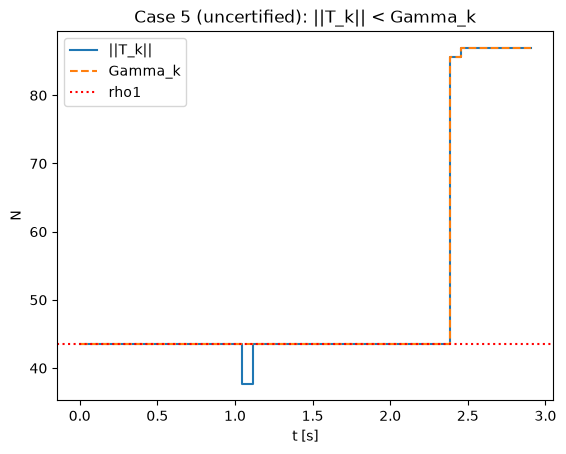

Thrust below rho1 in simulation (N): 5.810275306057839


In [35]:
if not lossy:
    print("No lossy case found (threshold 1e-3): nothing to plot.")
else:
    c = max(lossy, key=lambda i: rows_nc[i]["gap"])     # most lossy case
    x0c, m0c = B1_CASES[c][:4], P.m_dry + B1_CASES[c][4]
    solc = make_guidance(False)(x0c, m0c)

    Tn = np.linalg.norm(solc.thrust, axis=1)              # thrust actually requested
    G = solc.sigma * np.exp(solc.z[:-1])                  # Gamma_k, the thrust "paid for"
    plt.step(solc.t[:-1], Tn, where="post", label="||T_k||")
    plt.step(solc.t[:-1], G, where="post", ls="--", label="Gamma_k")
    plt.axhline(P.rho1, color="r", ls=":", label="rho1")
    plt.xlabel("t [s]"); plt.ylabel("N"); plt.legend()
    plt.title(f"Case {c} (uncertified): ||T_k|| < Gamma_k")
    plt.show()

    sim = simulate(solc)
    print("Thrust below rho1 in simulation (N):", sim["thrust_violation"])

In [38]:
rows = run_b1(make_guidance(True), d_star_fn)
df = pd.DataFrame(rows)
df["fuel_g"] = 1000 * df["fuel"]
df["d_land_cm"] = 100 * df["d_land"]
display(df[["case", "reachable", "landed", "d_land_cm", "fuel_g",
            "viol_T", "viol_gs", "gap", "t_solve", "d_star"]])
print(f"Successful landings: {df.landed.sum()}/20 | "
      f"mean solve time: {df.t_solve.mean():.2f} s")

,case,reachable,landed,d_land_cm,fuel_g,viol_T,viol_gs,gap,t_solve,d_star
0,0,True,True,5.314176e-09,131.780507,0.019209,0.000000,2.471688e-05,0.690554,NaN
1,1,True,True,8.255246e-09,115.443450,0.022546,0.000000,6.388801e-04,0.583452,NaN
2,2,True,True,4.831987e-09,123.889868,0.023401,0.000000,7.529875e-04,0.595698,NaN
3,3,True,True,1.935072e-09,158.869513,0.030453,0.000000,3.590968e-04,0.547811,NaN
4,4,True,True,1.457661e-08,137.463532,0.025231,0.000000,4.137077e-04,0.524876,NaN
5,5,True,True,9.010303e-09,159.359265,0.031251,0.000000,6.953640e-04,0.600922,NaN
6,6,True,True,4.983166e-09,165.372541,0.032306,0.000000,7.697440e-04,0.520789,NaN
7,7,True,True,3.444615e-08,154.496678,0.025849,0.000000,2.689070e-04,0.505336,NaN
8,8,True,True,5.902874e-09,131.865990,0.023044,0.000000,2.023811e-04,0.558946,NaN
9,9,True,True,3.785810e-09,127.117638,0.023133,0.000000,5.273264e-04,0.560105,NaN


Successful landings: 20/20 | mean solve time: 0.68 s


### Question 4

In [48]:
N_SEEDS = 10        # 100 for the final report
PROCESSES = 2

POLICIES = {
    "LCvx cascade": "lander.controllers:make_cascade",
    "Heuristic": "submissions/baseline_heuristic.py",
    "PPO": "submissions/baseline_ppo.py",
}
CONDITIONS = ("nominal", "heavy", "light", "gusty", "storm")

In [51]:
summaries = {}
with tempfile.TemporaryDirectory() as tmp:
    for name, source in POLICIES.items():
        result = Path(tmp) / f"{name.replace(' ', '_')}.json"
        cmd = [sys.executable, "-m", "lander.evaluate", "--policy", source,
               "--benchmark", "b2", "--n", str(N_SEEDS),
               "--processes", str(PROCESSES), "--out", str(result)]
        print(f"=== {name} ({N_SEEDS} seeds / condition) ===", flush=True)
        run = subprocess.run(cmd, capture_output=True, text=True)
        print(run.stdout[-1500:])                          # last lines of the evaluator output
        if run.returncode != 0:
            print(run.stderr[-3000:])
            raise RuntimeError(f"{name} failed")
        summaries[name] = json.loads(result.read_text())["summary"]

=== LCvx cascade (10 seeds / condition) ===
{
 "score": 87.69848817556098,
 "n": 50,
 "success": 1.0,
 "off_pad": 0.0,
 "hazard": 0.0,
 "crash": 0.0,
 "hard": 0.0,
 "out": 0.0,
 "timeout": 0.0,
 "fuel_success": 2.4603023648878035,
 "vy_success": 1.145518229007721,
 "policy_ms": 1.416791978427912
}
nominal : score    86.3  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.74  ms 1.4
heavy   : score    87.0  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.59  ms 1.8
light   : score    90.7  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 1.86  ms 1.5
gusty   : score    88.3  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.33  ms 1.2
storm   : score    86.1  success 1.00  hazard 0.00  crash 0.00  off_pad 0.00  out 0.00  timeout 0.00  fuel 2.78  ms 1.3

=== Heuristic (10 seeds / condition) ===
{
 "score": 72.72696239054203,
 "n": 50,
 "success": 0.8,
 

In [52]:
def num(x):
    return x if math.isfinite(x) else float("nan")

overall = pd.DataFrame([{
    "Policy": name,
    "Success (%)": 100 * s["overall"]["success"],
    "Mean score": num(s["overall"]["score"]),
    "Fuel (s, successes)": num(s["overall"]["fuel_success"]),
    "Time (ms/step)": num(s["overall"]["policy_ms"]),
} for name, s in summaries.items()])
display(overall.round(2))

,Policy,Success (%),Mean score,"Fuel (s, successes)",Time (ms/step)
0,LCvx cascade,100.0,87.70,2.46,1.42
1,Heuristic,80.0,72.73,1.89,0.03
2,PPO,76.0,64.35,3.34,0.86


In [53]:
rows = []
for c in CONDITIONS:
    for name, s in summaries.items():
        a = s["per_scenario"][c]
        rows.append({
            "Environment": c, "Policy": name,
            "Success (%)": 100 * a["success"],
            "Fuel (s, successes)": num(a["fuel_success"]),
            "Time (ms/step)": num(a["policy_ms"]),
            "Off-pad (%)": 100 * a["off_pad"],
            "Crash/hard (%)": 100 * (a["crash"] + a["hard"]),
        })
display(pd.DataFrame(rows).round(2))

,Environment,Policy,Success (%),"Fuel (s, successes)",Time (ms/step),Off-pad (%),Crash/hard (%)
0,nominal,LCvx cascade,100.0,2.74,1.37,0.0,0.0
1,nominal,Heuristic,90.0,1.87,0.04,10.0,0.0
2,nominal,PPO,100.0,3.31,0.94,0.0,0.0
3,heavy,LCvx cascade,100.0,2.59,1.79,0.0,0.0
4,heavy,Heuristic,70.0,1.76,0.04,0.0,30.0
5,heavy,PPO,90.0,2.83,0.90,10.0,0.0
6,light,LCvx cascade,100.0,1.86,1.47,0.0,0.0
7,light,Heuristic,100.0,1.45,0.03,0.0,0.0
8,light,PPO,100.0,3.84,0.88,0.0,0.0
9,gusty,LCvx cascade,100.0,2.33,1.19,0.0,0.0
